### Selección de características por multicolinealidad (SVM)

Define qué características del tráfico de red entran al entrenamiento del SVM. Se descartan las que no varían, tres indicadores de bandera TCP con muy poca información sobre la clase y las que repiten la información de otra característica.

**Entrada.** `data/processed/wednesday_low_and_slow_clean.csv`, generado por `limpieza_low_and_slow.ipynb`. Si cambia `clean.py`, hay que regenerar el CSV antes de correr este cuaderno, que comprueba que el archivo corresponde a la versión vigente de la limpieza.

**Salida.** `reports/svm/columnas_multicolineales.json`, con las columnas a eliminar y los parámetros que produjeron la decisión. `02_Feature_Engineering.ipynb` lee este archivo en lugar de recalcular la selección.

**Decisiones de diseño**

1. Todo cálculo que usa la etiqueta o la estructura de correlación se hace solo con la partición de entrenamiento, para que validación y prueba no influyan en la selección.
2. La asociación entre características se mide con la correlación de Spearman, que es robusta a valores atípicos y no cambia con transformaciones monótonas, como el logaritmo que se aplica después al escalar.
3. La relevancia de cada característica se mide con información mutua, que captura también relaciones no lineales.
4. La redundancia se elimina con un procedimiento voraz: se recorren las características de mayor a menor relevancia y cada una se descarta si su correlación absoluta con alguna ya conservada supera el umbral. Así no se encadenan características que no se parecen entre sí, como pasa al agrupar por componentes conexas.

**Contenido**

1. Carga y partición de los datos
2. Características constantes y casi constantes
3. Relevancia de cada característica
4. Banderas TCP excluidas
5. Correlación de Spearman
6. Selección voraz por redundancia
7. Sensibilidad al umbral
8. Características citadas en el protocolo
9. Verificación y guardado de la decisión

In [ ]:
# Librerías y parámetros del cuaderno. Todo valor ajustable está en esta celda
# y se guarda en el JSON de salida junto con la decisión.

import sys
sys.path.append("../..") 

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split

from src.preprocessing.clean import (
    cargar_dataset_limpio,
    train_test_split_by_flow,
    COLUMNAS_A_ELIMINAR_CANDIDATAS,
    COLUMNAS_ATAJO_LABORATORIO,
    COLUMNAS_REDUNDANTES,
    COLUMNAS_CONSTANTES,
    HORA_INICIO_CAPTURA,
    HORA_FIN_CAPTURA,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
sns.set_style("whitegrid")

# Semilla del muestreo y de la estimación de información mutua
RANDOM_STATE = 42

# CSV limpio generado por limpieza_low_and_slow.ipynb
RUTA_CSV = "../../data/processed/wednesday_low_and_slow_clean.csv"

# Una característica es casi constante si su valor más frecuente ocupa al menos esta
# proporción de las filas
UMBRAL_CASI_CONSTANTE = 0.999

# Banderas TCP excluidas por parsimonia (sección 4)
COLUMNAS_SIN_INFORMACION = ["URG Flag Count", "ACK Flag Count", "FIN Flag Count"]

# |Spearman| por encima del cual dos características se consideran redundantes
# (la sección 7 muestra cómo cambia la selección con este valor)
UMBRAL = 0.98

# Se conservan siempre, aunque otra de mayor relevancia las duplique.
# Flow Duration aparece en los objetivos específicos del protocolo
FORZAR_CONSERVAR = ["Flow Duration"]

# Parámetros de la partición cronológica. Vacío usa los valores por defecto de clean.py;
# deben ser los mismos en los tres cuadernos
PARAMS_SPLIT = {}

# Salidas: la decisión (se versiona) y las tablas de apoyo
OUT_DIR = Path("../../reports/svm")
FIG_DIR = Path("../../reports/figures/svm")
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

**1. Carga y partición de los datos**

`cargar_dataset_limpio()` lee el CSV y convierte `Timestamp` a fecha. Después se comprueba que el archivo corresponde a la versión vigente de `clean.py`: reloj de 24 horas, sin las columnas que elimina la limpieza y sin nulos. Si algo falla, hay que volver a correr `limpieza_low_and_slow.ipynb`.

Luego se aplica la partición cronológica y solo se conserva el entrenamiento. Validación y prueba se eliminan de memoria de inmediato para que ningún cálculo posterior pueda usarlas.

In [2]:
# El CSV debe corresponder a la versión vigente de clean.py; si no, fallan las aserciones
df = cargar_dataset_limpio(RUTA_CSV)

# Timestamp en tipo fecha y reloj de 24 horas (debe haber tráfico de la tarde)
assert pd.api.types.is_datetime64_any_dtype(df["Timestamp"]), "Timestamp no es de tipo fecha"
horas = df["Timestamp"].dt.hour
assert horas.between(HORA_INICIO_CAPTURA, HORA_FIN_CAPTURA).all(), "Horas fuera del horario de captura"
assert horas.max() >= 13, "El CSV no contiene la corrección del reloj de 12 horas"

# Las columnas que elimina la limpieza no deben estar en el CSV
eliminadas = (COLUMNAS_A_ELIMINAR_CANDIDATAS + COLUMNAS_ATAJO_LABORATORIO
              + COLUMNAS_REDUNDANTES + COLUMNAS_CONSTANTES)
presentes = [c for c in eliminadas if c in df.columns]
assert not presentes, f"Columnas que la limpieza debió eliminar siguen en el CSV: {presentes}"

# Sin valores nulos
assert not df.isna().any().any(), "Existen valores nulos en el CSV"

print(f"CSV cargado: {len(df):,} filas x {df.shape[1]} columnas | "
      f"rango {df['Timestamp'].min()} -> {df['Timestamp'].max()}")
n_filas_dataset = len(df)

# Partición cronológica por bloques
(X_train, X_val, X_test, y_train, y_val, y_test,
 meta_train, meta_val, meta_test) = train_test_split_by_flow(df, return_meta=True, **PARAMS_SPLIT)

# Validación y prueba no se usan aquí; se liberan para que ningún cálculo las toque
n_val, n_test = len(X_val), len(X_test)
del X_val, X_test, y_val, y_test, meta_val, meta_test, df

# Timestamp y bloque son metadatos de la partición, no características. Se comprueba
# que el resto sea numérico y que la etiqueta no esté en la matriz de entrada
COLUMNAS_METADATA = ["Timestamp", "bloque"]
features = [c for c in X_train.columns if c not in COLUMNAS_METADATA]
X = X_train[features]

no_numericas = [c for c in features if not pd.api.types.is_numeric_dtype(X[c])]
assert not no_numericas, f"Características no numéricas: {no_numericas}"
assert "Label" not in X_train.columns and "label_binaria" not in X_train.columns

print(f"\nEntrenamiento: {len(X):,} filas x {len(features)} características | "
      f"proporción de ataques: {y_train.mean():.4%}")
print(f"(Validación: {n_val:,} filas y prueba: {n_test:,} filas; no se utilizan en este cuaderno)")

CSV cargado: 443,614 filas x 62 columnas | rango 2017-07-05 08:42:00 -> 2017-07-05 17:10:00
Fronteras de bloque (outlier_quantile=0.0, desempate=csv):
  Slowloris:    [2017-07-05 09:48:00 .. 2017-07-05 10:11:00]  (5790 filas)
  Slowhttptest: [2017-07-05 10:15:00 .. 2017-07-05 10:37:00]  (5499 filas)

Composición por bloque:
  Bloque 1: 53375 filas | Timestamp [2017-07-05 08:42:00 .. 2017-07-05 09:47:00] | ataques: 0 (0.00%)
  Bloque 2: 30362 filas | Timestamp [2017-07-05 09:48:00 .. 2017-07-05 10:11:00] | ataques: 5790 (19.07%)
  Bloque 3: 3578 filas | Timestamp [2017-07-05 10:12:00 .. 2017-07-05 10:14:00] | ataques: 0 (0.00%)
  Bloque 4: 33203 filas | Timestamp [2017-07-05 10:15:00 .. 2017-07-05 10:37:00] | ataques: 5499 (16.56%)
  Bloque 5: 323096 filas | Timestamp [2017-07-05 10:38:00 .. 2017-07-05 17:10:00] | ataques: 0 (0.00%)

Train: 310529 filas | Val: 66541 filas | Test: 66544 filas
Proporción de ataques -> train: 0.0265, val: 0.0283, test: 0.0177

Entrenamiento: 310,529 filas 

**2. Características constantes y casi constantes**

Una característica constante no discrimina y su correlación no está definida. Una casi constante (un solo valor en casi todas las filas, ver `UMBRAL_CASI_CONSTANTE`) causa otro problema: al estandarizar, las pocas filas distintas toman magnitudes enormes, dominan las distancias del kernel de base radial (RBF) y quedan aisladas del resto.

Se calcula la proporción de filas que ocupa el valor más frecuente de cada característica y se excluyen las que llegan al umbral, antes de cualquier otro cálculo.

In [3]:
# Proporción de filas que ocupa el valor más frecuente de cada característica
proporcion_dominante = X.apply(lambda s: s.value_counts(normalize=True).iloc[0])

# Constantes: proporción = 1. Casi constantes: entre el umbral y 1
constantes = proporcion_dominante[proporcion_dominante == 1.0].index.tolist()
casi_constantes = proporcion_dominante[
    (proporcion_dominante >= UMBRAL_CASI_CONSTANTE) & (proporcion_dominante < 1.0)
].index.tolist()

print(f"Umbral de casi constancia: {UMBRAL_CASI_CONSTANTE}")
print(f"Características constantes en entrenamiento: {constantes if constantes else 'ninguna'}")
print(f"Características casi constantes en entrenamiento: {casi_constantes if casi_constantes else 'ninguna'}")

# Las diez con mayor proporción dominante, como referencia
print("\nDiez características con mayor proporción de valor dominante:")
print(proporcion_dominante.sort_values(ascending=False).head(10).round(6).to_string())

features_var = [c for c in features if c not in set(constantes) | set(casi_constantes)]
print(f"\nCaracterísticas con variación suficiente: {len(features_var)}")

# FORZAR_CONSERVAR no debe haber quedado fuera
faltan = [f for f in FORZAR_CONSERVAR if f not in features_var]
assert not faltan, f"FORZAR_CONSERVAR contiene columnas excluidas o ausentes: {faltan}"

Umbral de casi constancia: 0.999
Características constantes en entrenamiento: ninguna
Características casi constantes en entrenamiento: ['RST Flag Count', 'ECE Flag Count']

Diez características con mayor proporción de valor dominante:
RST Flag Count    0.999697
ECE Flag Count    0.999697
FIN Flag Count    0.981416
SYN Flag Count    0.940550
URG Flag Count    0.899368
Active Std        0.898010
Idle Std          0.891067
Active Mean       0.824548
Active Max        0.824548
Active Min        0.824548

Características con variación suficiente: 57


**3. Relevancia de cada característica**

La relevancia es la información mutua (en nats) entre la característica y la clase. Detecta dependencias lineales y no lineales, algo pertinente para un SVM con kernel RBF. Se usa para ordenar las características en la selección voraz (sección 6), de modo que entre dos equivalentes se conserve la más informativa, y para respaldar la decisión de la sección 4.

La estimación usa una muestra estratificada de hasta 50 000 flujos de entrenamiento, con las variables en escala logarítmica con signo (admite negativos, como el `-1` de `Init_Win_bytes_*`). Las características con diez valores distintos o menos se tratan como discretas y entran con sus valores originales.

In [4]:
# Muestra estratificada de entrenamiento; si hay menos filas que n_muestra se usa todo
n_muestra = min(50_000, len(X))
if n_muestra < len(X):
    X_s, _, y_s, _ = train_test_split(
        X[features_var], y_train, train_size=n_muestra, stratify=y_train, random_state=RANDOM_STATE
    )
else:
    X_s, y_s = X[features_var], y_train

# Log con signo: sign(x) * log1p(|x|). Admite negativos (p. ej. el -1 de Init_Win_bytes_*)
X_s_log = np.sign(X_s) * np.log1p(np.abs(X_s))

# Con 10 valores distintos o menos se tratan como discretas y no se transforman
discretas = (X_s.nunique() <= 10).to_numpy()
X_s_log.loc[:, discretas] = X_s.loc[:, discretas]

# Información mutua (nats) de cada característica con la etiqueta
relevancia_completa = pd.Series(
    mutual_info_classif(X_s_log, y_s, discrete_features=discretas, random_state=RANDOM_STATE),
    index=features_var,
).sort_values(ascending=False)

print(f"Información mutua con la etiqueta (muestra de {n_muestra:,} flujos de entrenamiento). "
      "Quince valores más altos:")
print(relevancia_completa.head(15).round(4).to_string())

Información mutua con la etiqueta (muestra de 50,000 flujos de entrenamiento). Quince valores más altos:
Flow IAT Max                   0.0989
Fwd IAT Max                    0.0986
Flow Packets/s                 0.0982
Flow IAT Mean                  0.0976
Fwd Packets/s                  0.0963
Flow Duration                  0.0959
Fwd IAT Mean                   0.0957
Fwd IAT Total                  0.0912
Flow IAT Std                   0.0908
Max Packet Length              0.0827
Fwd Packet Length Max          0.0815
Fwd IAT Std                    0.0759
Total Length of Fwd Packets    0.0745
Fwd IAT Min                    0.0742
Packet Length Mean             0.0727


**4. Banderas TCP excluidas**

Se excluyen `URG Flag Count`, `ACK Flag Count` y `FIN Flag Count` por parsimonia. La tabla muestra su información mutua con la etiqueta y la proporción de su valor dominante como respaldo.

Es una decisión de diseño, no el resultado de un procedimiento automático. Su efecto en el desempeño no se mide aquí; puede contrastarse en la fase de ablación del entrenamiento.

In [5]:
# Todas las columnas a excluir deben existir
ausentes = [c for c in COLUMNAS_SIN_INFORMACION if c not in features]
assert not ausentes, f"COLUMNAS_SIN_INFORMACION contiene columnas inexistentes: {ausentes}"

# Solo las que no salieron ya por constancia
sin_informacion = [c for c in COLUMNAS_SIN_INFORMACION if c in features_var]

# Respaldo de la decisión: información mutua y valor dominante de cada columna excluida
respaldo = pd.DataFrame({
    "informacion_mutua": relevancia_completa[sin_informacion],
    "proporcion_valor_dominante": proporcion_dominante[sin_informacion],
})
display(respaldo.round(4))

features_var = [c for c in features_var if c not in sin_informacion]
relevancia = relevancia_completa[features_var].sort_values(ascending=False)

assert all(f in features_var for f in FORZAR_CONSERVAR), "Se excluyó una característica obligatoria"
print(f"Características restantes para el análisis de correlación: {len(features_var)}")

,informacion_mutua,proporcion_valor_dominante
URG Flag Count,0.0001,0.8994
ACK Flag Count,0.0000,0.7267
FIN Flag Count,0.0005,0.9814


Características restantes para el análisis de correlación: 54


**5. Correlación de Spearman (solo entrenamiento)**

Se calcula la correlación de Spearman entre todas las parejas de características restantes. Equivale a la correlación de Pearson sobre los rangos, así que no depende de la escala y es robusta a valores atípicos, algo útil en variables que cubren varios órdenes de magnitud.

Se listan las parejas con valor absoluto mayor que 0.90 para dejar constancia de las redundancias candidatas.

In [6]:
# Spearman = Pearson sobre los rangos
rho = X[features_var].rank().corr()
assert not rho.isna().any().any(), "La matriz de correlación contiene valores indefinidos"

# Triángulo superior de la matriz como tabla de parejas
mascara_superior = np.triu(np.ones(rho.shape, dtype=bool), k=1)
pares = (
    rho.where(mascara_superior)
    .stack()
    .rename("rho")
    .reset_index()
    .set_axis(["Feature 1", "Feature 2", "rho"], axis=1)
)
pares["abs_rho"] = pares["rho"].abs()
pares_altos = pares[pares["abs_rho"] > 0.90].sort_values("abs_rho", ascending=False)

print(f"Parejas con |Spearman| > 0.90: {len(pares_altos)}")
print(f"Parejas con |Spearman| > {UMBRAL}: {int((pares['abs_rho'] > UMBRAL).sum())}\n")
with pd.option_context("display.max_rows", None):
    display(pares_altos.drop(columns="abs_rho").round(4).reset_index(drop=True))

pares_altos.drop(columns="abs_rho").to_csv(FIG_DIR / "pares_alta_correlacion_train.csv", index=False)

Parejas con |Spearman| > 0.90: 62
Parejas con |Spearman| > 0.98: 30



,Feature 1,Feature 2,rho
0,Packet Length Std,Packet Length Variance,1.0000
1,Idle Mean,Idle Max,0.9993
2,Active Mean,Active Max,0.9986
3,Idle Mean,Idle Min,0.9982
4,Bwd IAT Mean,Bwd IAT Max,0.9981
5,Bwd IAT Total,Bwd IAT Max,0.9973
6,Idle Max,Idle Min,0.9968
7,Bwd IAT Total,Bwd IAT Mean,0.9965
8,Fwd IAT Total,Fwd IAT Max,0.9962
9,Flow Packets/s,Fwd Packets/s,0.9961


**6. Selección voraz por redundancia**

1. Las características se ordenan por relevancia decreciente; las de `FORZAR_CONSERVAR` van primero.
2. Se recorren en ese orden. Una característica se descarta si su correlación absoluta con alguna ya conservada supera `UMBRAL`; si no, se conserva.

Con esto, (a) ninguna pareja de características conservadas supera el umbral y (b) cada descartada tiene una pareja conservada por encima del umbral, que queda registrada como justificación.

In [7]:
def seleccionar_por_redundancia(rho, relevancia, umbral, forzar=()):
    """Selección voraz de características por redundancia.

    Recorre las características de mayor a menor relevancia (primero las de `forzar`) y
    descarta las que tienen |rho| > `umbral` con alguna ya conservada.

    Args:
        rho: matriz de correlación de Spearman.
        relevancia: Series con la información mutua de cada característica.
        umbral: valor absoluto de rho a partir del cual hay redundancia.
        forzar: características que se conservan siempre.

    Returns:
        (conservadas, descartadas), con descartadas = {característica: (pareja, |rho|)}.
    """
    orden = list(forzar) + [f for f in relevancia.index if f not in forzar]
    conservadas, descartadas = [], {}
    for f in orden:
        if conservadas:
            r = rho.loc[f, conservadas].abs()
            if r.max() > umbral:
                descartadas[f] = (r.idxmax(), float(r.max()))
                continue
        conservadas.append(f)
    return conservadas, descartadas


conservadas, descartadas = seleccionar_por_redundancia(rho, relevancia, UMBRAL, FORZAR_CONSERVAR)
conservadas_set = set(conservadas)

print(f"Umbral |Spearman| > {UMBRAL}")
print(f"Características conservadas: {len(conservadas)} | descartadas por redundancia: {len(descartadas)}")

# Cada descartada con la pareja conservada que la duplica y la información mutua de ambas
tabla = pd.DataFrame([
    {"descartada": f, "redundante_con": k, "abs_rho": r,
     "MI_descartada": relevancia[f], "MI_conservada": relevancia[k]}
    for f, (k, r) in descartadas.items()
]).sort_values("abs_rho", ascending=False).reset_index(drop=True)

if len(tabla):
    display(tabla.round(4))
    tabla.to_csv(FIG_DIR / "redundancias_descartadas.csv", index=False)
else:
    print("No se descartó ninguna característica por redundancia.")

Umbral |Spearman| > 0.98
Características conservadas: 39 | descartadas por redundancia: 15


,descartada,redundante_con,abs_rho,MI_descartada,MI_conservada
0,Packet Length Std,Packet Length Variance,1.0000,0.0675,0.0682
1,Idle Mean,Idle Max,0.9993,0.0642,0.0644
2,Bwd IAT Mean,Bwd IAT Max,0.9981,0.0483,0.0487
3,Bwd IAT Total,Bwd IAT Max,0.9973,0.0434,0.0487
4,Idle Min,Idle Max,0.9968,0.0590,0.0644
5,Fwd IAT Total,Fwd IAT Max,0.9962,0.0912,0.0986
6,Fwd Packets/s,Flow Packets/s,0.9961,0.0963,0.0982
7,Flow IAT Mean,Flow Packets/s,0.9961,0.0976,0.0982
8,Fwd IAT Mean,Fwd IAT Max,0.9952,0.0957,0.0986
9,Average Packet Size,Packet Length Mean,0.9934,0.0692,0.0727


**Revisión de las descartadas.** Se compara la información mutua de cada descartada con la de su pareja conservada. Que la descartada tenga más solo puede pasar cuando la pareja está en `FORZAR_CONSERVAR`, y amerita revisar la decisión a mano. También se listan las diez descartadas con más información mutua, que son las de mayor costo potencial.

In [8]:
# MI_perdida > 0: la descartada era más informativa que su pareja conservada
if len(tabla):
    tabla["MI_perdida"] = tabla["MI_descartada"] - tabla["MI_conservada"]

    print("Descartadas con mayor información mutua que su pareja conservada:")
    revisar = tabla[tabla["MI_perdida"] > 0].sort_values("MI_perdida", ascending=False)
    display(revisar.round(4) if len(revisar) else "ninguna")

    print("\nDiez descartadas con mayor información mutua:")
    display(tabla.sort_values("MI_descartada", ascending=False).head(10).round(4))

Descartadas con mayor información mutua que su pareja conservada:


,descartada,redundante_con,abs_rho,MI_descartada,MI_conservada,MI_perdida
11,Flow IAT Max,Flow Duration,0.9912,0.0989,0.0959,0.003



Diez descartadas con mayor información mutua:


,descartada,redundante_con,abs_rho,MI_descartada,MI_conservada,MI_perdida
11,Flow IAT Max,Flow Duration,0.9912,0.0989,0.0959,0.0030
7,Flow IAT Mean,Flow Packets/s,0.9961,0.0976,0.0982,-0.0006
6,Fwd Packets/s,Flow Packets/s,0.9961,0.0963,0.0982,-0.0019
8,Fwd IAT Mean,Fwd IAT Max,0.9952,0.0957,0.0986,-0.0029
5,Fwd IAT Total,Fwd IAT Max,0.9962,0.0912,0.0986,-0.0074
9,Average Packet Size,Packet Length Mean,0.9934,0.0692,0.0727,-0.0035
0,Packet Length Std,Packet Length Variance,1.0000,0.0675,0.0682,-0.0007
1,Idle Mean,Idle Max,0.9993,0.0642,0.0644,-0.0001
13,Active Mean,Idle Max,0.9848,0.0637,0.0644,-0.0006
12,Active Max,Idle Max,0.9849,0.0636,0.0644,-0.0007


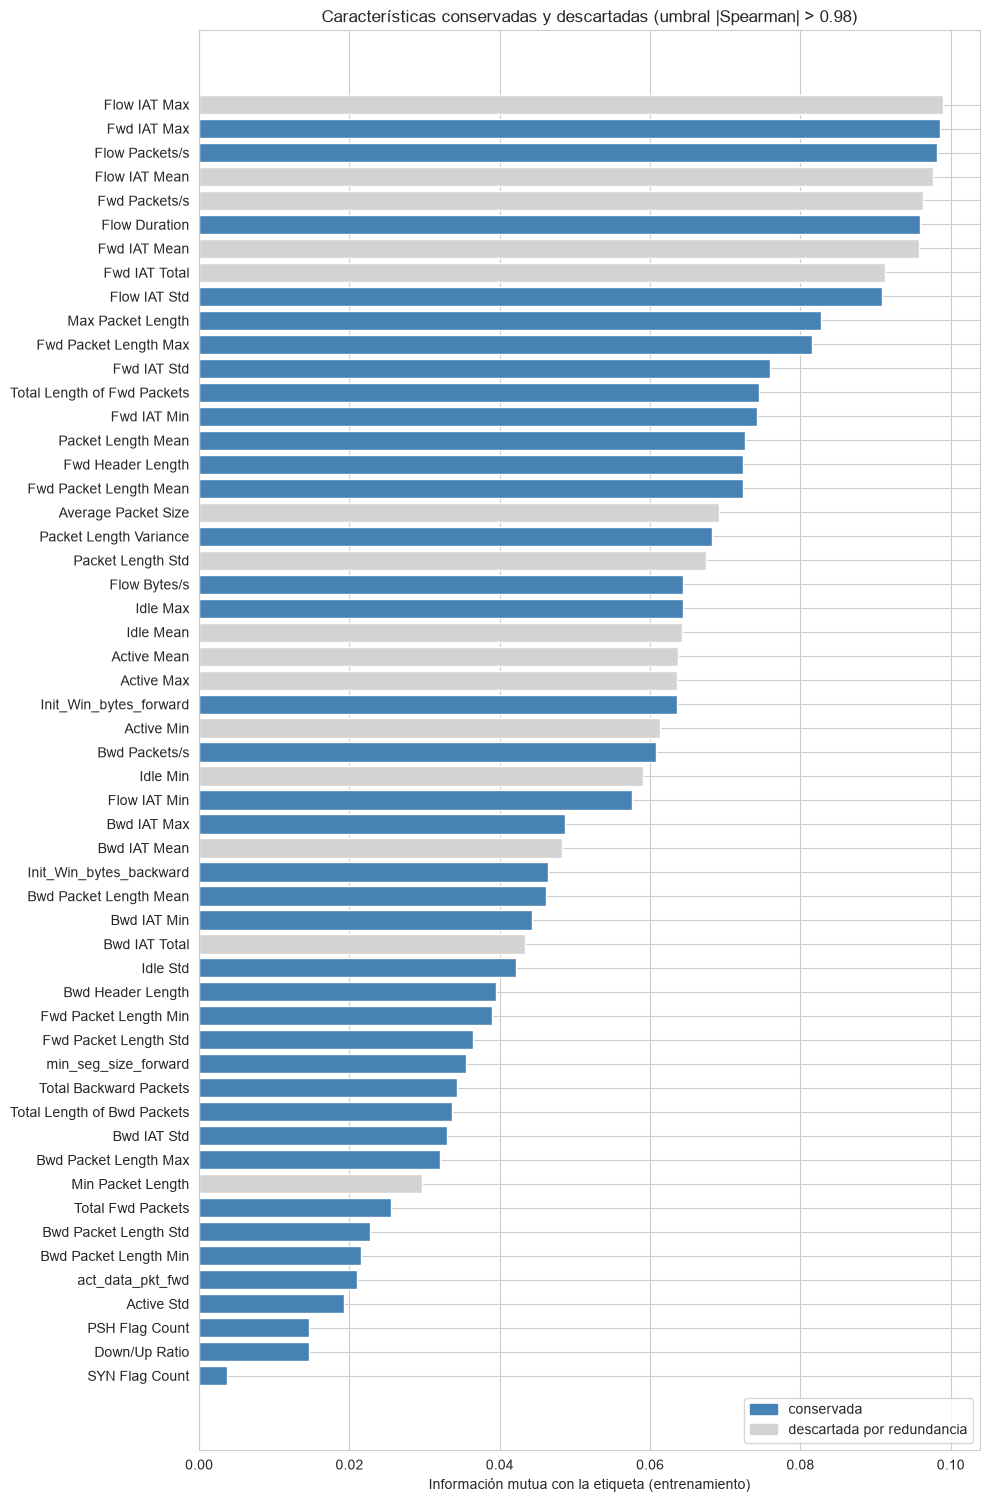

In [9]:
# Información mutua por característica: conservadas frente a descartadas por redundancia
orden_mi = relevancia.sort_values()
colores = ["steelblue" if f in conservadas_set else "lightgray" for f in orden_mi.index]

fig, ax = plt.subplots(figsize=(10, max(6, 0.28 * len(orden_mi))))
ax.barh(orden_mi.index, orden_mi.values, color=colores)
ax.set_xlabel("Información mutua con la etiqueta (entrenamiento)")
ax.set_title(f"Características conservadas y descartadas (umbral |Spearman| > {UMBRAL})")
ax.legend(handles=[Patch(color="steelblue", label="conservada"),
                   Patch(color="lightgray", label="descartada por redundancia")], loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "conservadas_vs_descartadas.png", dpi=150)
plt.show()

**7. Sensibilidad al umbral**

El número de características conservadas depende del umbral de correlación. Se repite la selección de la sección 6 con varios valores para ver qué tan estable es y respaldar la elección de `UMBRAL`. Los umbrales bajos eliminan características correlacionadas pero no idénticas; los altos conservan casi todas.

In [10]:
# Misma selección con distintos umbrales
filas = []
for u in (0.90, 0.95, 0.98, 0.99, 0.999):
    cons_u, desc_u = seleccionar_por_redundancia(rho, relevancia, u, FORZAR_CONSERVAR)
    filas.append({"umbral": u, "conservadas": len(cons_u), "descartadas": len(desc_u)})
sensibilidad = pd.DataFrame(filas)
display(sensibilidad)
sensibilidad.to_csv(FIG_DIR / "sensibilidad_umbral.csv", index=False)

,umbral,conservadas,descartadas
0,0.900,30,24
1,0.950,33,21
2,0.980,39,15
3,0.990,40,14
4,0.999,52,2


**8. Características citadas en el protocolo**

El primer objetivo específico del protocolo menciona la duración de la conexión, el número de paquetes, el volumen de datos, la tasa de envío de paquetes y los intervalos entre solicitudes. La tabla indica qué pasó con las características asociadas a cada magnitud y, si alguna se descartó, cuál se conservó con información equivalente.

In [11]:
# Características asociadas a las magnitudes del primer objetivo específico del protocolo
CLAVE_PROTOCOLO = [
    "Flow Duration",
    "Total Fwd Packets", "Total Backward Packets",
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Flow Bytes/s", "Flow Packets/s",
    "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min",
    "Fwd IAT Mean", "Fwd IAT Max",
]

# Estado de cada una y, si se descartó, el motivo
filas = []
for f in CLAVE_PROTOCOLO:
    if f not in features:
        estado, detalle = "ausente", "no está en el conjunto de datos (eliminada en la limpieza)"
    elif f in constantes:
        estado, detalle = "excluida", "constante en entrenamiento"
    elif f in casi_constantes:
        estado, detalle = "excluida", "casi constante en entrenamiento"
    elif f in sin_informacion:
        estado, detalle = "excluida", "exclusión por baja capacidad discriminativa"
    elif f in descartadas:
        k, r = descartadas[f]
        estado, detalle = "descartada", f"redundante con {k} (|rho| = {r:.3f})"
    else:
        estado, detalle = "conservada", ""
    filas.append({"característica": f, "estado": estado, "detalle": detalle})
display(pd.DataFrame(filas))

,característica,estado,detalle
0,Flow Duration,conservada,
1,Total Fwd Packets,conservada,
2,Total Backward Packets,conservada,
3,Total Length of Fwd Packets,conservada,
4,Total Length of Bwd Packets,conservada,
5,Flow Bytes/s,conservada,
6,Flow Packets/s,conservada,
7,Flow IAT Mean,descartada,redundante con Flow Packets/s (|rho| = 0.996)
8,Flow IAT Std,conservada,
9,Flow IAT Max,descartada,redundante con Flow Duration (|rho| = 0.991)


**9. Verificación y guardado de la decisión**

Se comprueba que (a) las características de `FORZAR_CONSERVAR` siguen en el conjunto final y (b) ninguna pareja de las conservadas supera el umbral. Luego se reúnen las columnas a eliminar (constantes, casi constantes, banderas excluidas y redundantes) y se guarda la decisión en JSON junto con los parámetros que la produjeron. Con ese archivo, `02_Feature_Engineering.ipynb` comprueba que trabaja con los mismos datos y la misma partición.

In [12]:
# a) FORZAR_CONSERVAR sigue en el conjunto final
for f in FORZAR_CONSERVAR:
    assert f in conservadas_set, f"{f} debía conservarse"

# b) Ninguna pareja conservada supera el umbral
rho_cons = rho.loc[conservadas, conservadas].abs().to_numpy().copy()
np.fill_diagonal(rho_cons, 0)
assert rho_cons.max() <= UMBRAL, "Existen parejas de características conservadas sobre el umbral"
print(f"Máxima |Spearman| entre características conservadas: {rho_cons.max():.4f} (umbral {UMBRAL})")

# Columnas a eliminar: constantes, casi constantes, banderas excluidas y redundantes
columnas_a_eliminar = sorted(
    set(constantes) | set(casi_constantes) | set(sin_informacion) | set(descartadas)
)
columnas_conservadas = [c for c in features if c not in columnas_a_eliminar]
assert len(columnas_a_eliminar) + len(columnas_conservadas) == len(features)

# Decisión y parámetros que la produjeron. 02_Feature_Engineering.ipynb los usa para
# comprobar que trabaja con los mismos datos y la misma partición
resultado = {
    "criterio": "voraz por relevancia: se descarta una característica si |Spearman| con una ya conservada > umbral",
    "umbral_spearman": UMBRAL,
    "umbral_casi_constante": UMBRAL_CASI_CONSTANTE,
    "relevancia": f"información mutua con la etiqueta, solo entrenamiento (muestra de {n_muestra})",
    "random_state": RANDOM_STATE,
    "forzar_conservar": FORZAR_CONSERVAR,
    "params_split": PARAMS_SPLIT,
    "fuente_datos": RUTA_CSV,
    "n_filas_dataset": int(n_filas_dataset),
    "n_train": int(len(X_train)),
    "n_features_antes": len(features),
    "columnas_constantes_en_train": constantes,
    "columnas_casi_constantes_en_train": casi_constantes,
    "columnas_excluidas_sin_informacion": sin_informacion,
    "columnas_descartadas_por_redundancia": sorted(descartadas),
    "columnas_a_eliminar": columnas_a_eliminar,
    "columnas_conservadas": columnas_conservadas,
}
ruta_json = OUT_DIR / "columnas_multicolineales.json"
ruta_json.write_text(json.dumps(resultado, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Archivo guardado: {ruta_json.resolve()}")

Máxima |Spearman| entre características conservadas: 0.9777 (umbral 0.98)
Archivo guardado: C:\Users\juans\OneDrive\Documents\Github\low-and-slow-ids\reports\svm\columnas_multicolineales.json


In [13]:
# Resumen de la reducción por causa
print("Reducción de características por multicolinealidad (modelo SVM, solo entrenamiento)")
print(f"Filas de entrenamiento utilizadas:             {len(X_train):,}")
print(f"Características iniciales:                     {len(features)}")
print(f"Excluidas por constancia:                      {len(constantes)}")
print(f"Excluidas por casi constancia:                 {len(casi_constantes)}")
print(f"Excluidas por baja capacidad discriminativa:   {len(sin_informacion)}")
print(f"Descartadas por redundancia (|rho| > {UMBRAL}):   {len(descartadas)}")
print(f"Características finales:                       {len(columnas_conservadas)}")
print(f"\nColumnas a eliminar ({len(columnas_a_eliminar)}):")
for c in columnas_a_eliminar:
    print(f'    "{c}",')

Reducción de características por multicolinealidad (modelo SVM, solo entrenamiento)
Filas de entrenamiento utilizadas:             310,529
Características iniciales:                     59
Excluidas por constancia:                      0
Excluidas por casi constancia:                 2
Excluidas por baja capacidad discriminativa:   3
Descartadas por redundancia (|rho| > 0.98):   15
Características finales:                       39

Columnas a eliminar (20):
    "ACK Flag Count",
    "Active Max",
    "Active Mean",
    "Active Min",
    "Average Packet Size",
    "Bwd IAT Mean",
    "Bwd IAT Total",
    "ECE Flag Count",
    "FIN Flag Count",
    "Flow IAT Max",
    "Flow IAT Mean",
    "Fwd IAT Mean",
    "Fwd IAT Total",
    "Fwd Packets/s",
    "Idle Mean",
    "Idle Min",
    "Min Packet Length",
    "Packet Length Std",
    "RST Flag Count",
    "URG Flag Count",


**Uso de los resultados**

- `02_Feature_Engineering.ipynb` lee `reports/svm/columnas_multicolineales.json`, verifica que `n_filas_dataset`, `n_train` y `params_split` coincidan con los suyos y elimina las columnas de `columnas_a_eliminar`.
- La selección es específica del SVM y se apoya en las tablas de las secciones 6 y 7.
- Los criterios se calculan solo con entrenamiento. La decisión no debe ajustarse a mano con resultados de validación o prueba, salvo mediante el experimento de ablación documentado en el entrenamiento.
- Si cambia `clean.py`, el CSV procesado o los parámetros de la partición, hay que volver a correr este cuaderno.